# Book Recommender using a Medallion Data Lake

**Pipeline:** Raw files → Bronze → Silver → Gold → Recommender

- **Bronze** = raw copy of the data (nothing cleaned)
- **Silver** = cleaned data
- **Gold** = model-ready data
- **Recommender** = item-based collaborative filtering

## Step 0: Import libraries

In [1]:
import os
import zipfile
import re
import html
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from sklearn.neighbors import NearestNeighbors

## Step 1: Set up the Data Lake and build Bronze

First, upload the zip file `book-crossings.zip` from your computer.

In [2]:
# A file picker will appear. Choose book-crossings.zip
from google.colab import files
uploaded = files.upload()

Saving book-crossings.zip to book-crossings.zip


Unzip the file into a folder called `raw_data`.

In [3]:
zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("raw_data")

print("Files inside raw_data:", os.listdir("raw_data"))

Files inside raw_data: ['BX-Users.csv', 'BX-Book-Ratings.csv', 'BX-Books.csv']


Create the three data lake folders.

In [4]:
for folder in ["bronze", "silver", "gold"]:
    os.makedirs(folder, exist_ok=True)

print(os.listdir("."))

['.config', 'gold', 'bronze', 'book-crossings.zip', 'raw_data', 'silver', 'sample_data']


Read the raw files.

- Separator is `;`
- Encoding is `latin-1` (not UTF-8)
- `escapechar` fixes book rows that have quotes inside the title
- `dtype=str` keeps everything as plain text, exactly as in the source

In [5]:
users_raw = pd.read_csv("raw_data/BX-Users.csv", sep=";", encoding="latin-1", dtype=str)

books_raw = pd.read_csv("raw_data/BX-Books.csv", sep=";", encoding="latin-1",
                        dtype=str, escapechar="\\")

ratings_raw = pd.read_csv("raw_data/BX-Book-Ratings.csv", sep=";", encoding="latin-1", dtype=str)

print("Users  :", users_raw.shape)
print("Books  :", books_raw.shape)
print("Ratings:", ratings_raw.shape)

Users  : (278858, 3)
Books  : (271379, 8)
Ratings: (1149780, 3)


Add `ingestion_timestamp` and save to `bronze/` as Parquet. No cleaning here.

In [6]:
now = datetime.now()

users_raw["ingestion_timestamp"] = now
books_raw["ingestion_timestamp"] = now
ratings_raw["ingestion_timestamp"] = now

users_raw.to_parquet("bronze/users.parquet", index=False)
books_raw.to_parquet("bronze/books.parquet", index=False)
ratings_raw.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze saved:", os.listdir("bronze"))

Bronze saved: ['ratings.parquet', 'users.parquet', 'books.parquet']


## Step 2: Explore the Bronze data (EDA)

Read the Bronze tables back first.

In [7]:
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

### 2.1 Shape, data types, missing values

In [8]:
for name, df in [("USERS", users), ("BOOKS", books), ("RATINGS", ratings)]:
    print("=====", name, "=====")
    print("Shape:", df.shape)
    print(df.dtypes)
    print("Missing values:")
    print(df.isnull().sum())
    print()

===== USERS =====
Shape: (278858, 4)
User-ID                        object
Location                       object
Age                            object
ingestion_timestamp    datetime64[us]
dtype: object
Missing values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

===== BOOKS =====
Shape: (271379, 9)
ISBN                           object
Book-Title                     object
Book-Author                    object
Year-Of-Publication            object
Publisher                      object
Image-URL-S                    object
Image-URL-M                    object
Image-URL-L                    object
ingestion_timestamp    datetime64[us]
dtype: object
Missing values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0
dtype: int64


**Found:** All columns are text in Bronze. Age has 110,762 missing values. Books have 2 missing authors and 2 missing publishers.
**Silver:** Convert columns to proper types. Fill missing ages with the median.

### 2.2 Distribution of ratings

rating_num
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Ratings equal to 0: 716109
Percent of all ratings: 62.3 %


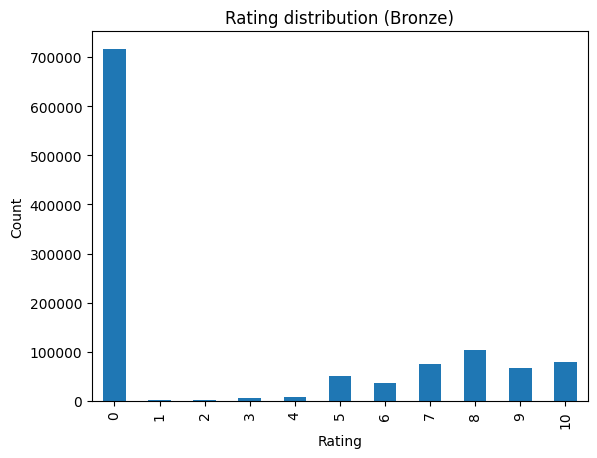

In [9]:
ratings["rating_num"] = ratings["Book-Rating"].astype(int)

rating_counts = ratings["rating_num"].value_counts().sort_index()
print(rating_counts)

zero_count = (ratings["rating_num"] == 0).sum()
print("\nRatings equal to 0:", zero_count)
print("Percent of all ratings:", round(zero_count / len(ratings) * 100, 1), "%")

rating_counts.plot(kind="bar", title="Rating distribution (Bronze)")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

**Found:** 716,109 ratings are 0 (about 62%). They mean "no explicit rating".
**Silver:** Remove all 0 ratings and keep 1 to 10.

### 2.3 Distribution of user ages

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Age below 5   : 882
Age above 100 : 366


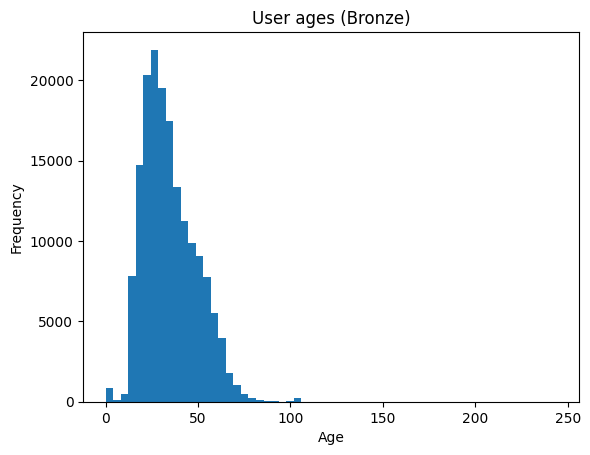

In [10]:
ages = pd.to_numeric(users["Age"], errors="coerce")

print(ages.describe())
print("\nAge below 5   :", (ages < 5).sum())
print("Age above 100 :", (ages > 100).sum())

ages.plot(kind="hist", bins=60, title="User ages (Bronze)")
plt.xlabel("Age")
plt.show()

**Found:** Impossible ages exist. 882 users are younger than 5 and 366 are older than 100 (max is 244).
**Silver:** Set those ages to null, then fill nulls with the median age.

### 2.4 Distribution of publication years

count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Year = 0            : 4619
Year in the future  : 11
Year between 1 and 1899: 4


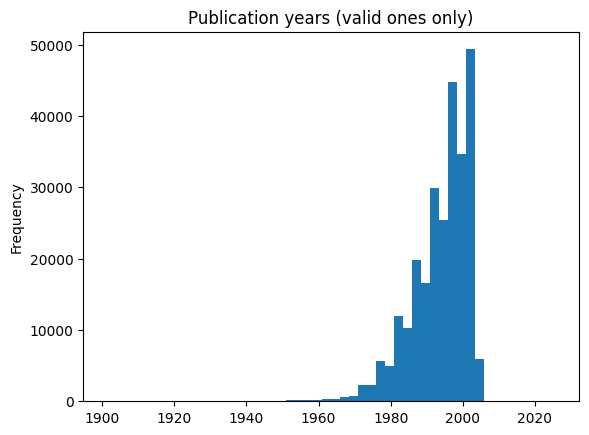

In [11]:
years = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
this_year = datetime.now().year

print(years.describe())
print("\nYear = 0            :", (years == 0).sum())
print("Year in the future  :", (years > this_year).sum())
print("Year between 1 and 1899:", ((years > 0) & (years < 1900)).sum())

years[(years > 1900) & (years <= this_year)].plot(kind="hist", bins=50,
                                                 title="Publication years (valid ones only)")
plt.show()

**Found:** 4,619 books have year 0 and 11 have a future year (up to 2050).
**Silver:** Set year 0 and future years to null.

### 2.5 Ratings per user and per book

In [12]:
per_user = ratings.groupby("User-ID").size()
per_book = ratings.groupby("ISBN").size()

print("Ratings per user:")
print(per_user.describe())
print("Users with 5 or fewer ratings:", round((per_user <= 5).mean() * 100, 1), "%")

print("\nRatings per book:")
print(per_book.describe())
print("Books with 5 or fewer ratings:", round((per_book <= 5).mean() * 100, 1), "%")

Ratings per user:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64
Users with 5 or fewer ratings: 81.3 %

Ratings per book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64
Books with 5 or fewer ratings: 89.8 %


**Found:** The median user and the median book both have only 1 rating. About 81% of users and 90% of books have 5 or fewer.
**Silver:** Keep only users and books with at least a minimum number of ratings (threshold is chosen in Step 3).

### 2.6 Matrix sparsity

In [13]:
n_users = ratings["User-ID"].nunique()
n_books = ratings["ISBN"].nunique()
possible = n_users * n_books

sparsity_pct = len(ratings) / possible * 100

print("Users who rated  :", n_users)
print("Books rated      :", n_books)
print("Possible pairs   :", possible)
print("Actual ratings   :", len(ratings))
print("Filled percent   :", round(sparsity_pct, 4), "%")
print("Empty percent    :", round(100 - sparsity_pct, 4), "%")

Users who rated  : 105283
Books rated      : 340556
Possible pairs   : 35854757348
Actual ratings   : 1149780
Filled percent   : 0.0032 %
Empty percent    : 99.9968 %


**Found:** Only about 0.003% of user-book pairs have a rating. The matrix is almost empty.
**Silver/Gold:** Store the matrix as a sparse matrix. Filtering will make it a bit denser.

## Step 3: Clean the data and build Silver

Start from the Bronze tables again and drop the helper column.

In [14]:
users = pd.read_parquet("bronze/users.parquet").drop(columns=["ingestion_timestamp"])
books = pd.read_parquet("bronze/books.parquet").drop(columns=["ingestion_timestamp"])
ratings = pd.read_parquet("bronze/ratings.parquet").drop(columns=["ingestion_timestamp"])

### 3.1 Rename columns and fix data types

In [15]:
users = users.rename(columns={"User-ID": "user_id", "Location": "location", "Age": "age"})

books = books.rename(columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
                              "Year-Of-Publication": "year", "Publisher": "publisher"})

ratings = ratings.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})

# turn text into numbers
users["user_id"] = users["user_id"].astype(int)
users["age"] = pd.to_numeric(users["age"], errors="coerce")

books["year"] = pd.to_numeric(books["year"], errors="coerce")

ratings["user_id"] = ratings["user_id"].astype(int)
ratings["rating"] = ratings["rating"].astype(int)

# clean the ISBN early, so duplicates are found correctly
books["isbn"] = books["isbn"].str.strip().str.upper()
ratings["isbn"] = ratings["isbn"].str.strip().str.upper()

### 3.2 Remove duplicates

In [16]:
print("Before ->", len(users), len(books), len(ratings))

users = users.drop_duplicates(subset="user_id")
books = books.drop_duplicates(subset="isbn")
ratings = ratings.drop_duplicates(subset=["user_id", "isbn"])

print("After  ->", len(users), len(books), len(ratings))

Before -> 278858 271379 1149780
After  -> 278858 271064 1149780


### 3.3 Remove ratings of 0

In [17]:
print("Before:", len(ratings))
ratings = ratings[ratings["rating"] > 0]
print("After :", len(ratings))
print("Rating range now:", ratings["rating"].min(), "to", ratings["rating"].max())

Before: 1149780
After : 433671
Rating range now: 1 to 10


### 3.4 Fix user ages

In [18]:
# impossible ages become null
users.loc[(users["age"] < 5) | (users["age"] > 100), "age"] = np.nan

median_age = users["age"].median()
print("Median age:", median_age)

# fill all nulls with the median
users["age"] = users["age"].fillna(median_age)
print("Missing ages left:", users["age"].isnull().sum())

Median age: 32.0
Missing ages left: 0


### 3.5 Split location into city, state, country

In [19]:
def split_location(text):
    # location looks like: "city, state, country"
    parts = [p.strip() for p in str(text).split(",")]
    city = parts[0]
    country = parts[-1]
    if len(parts) >= 3:
        state = parts[1]
    else:
        state = ""
    return city, state, country

locations = users["location"].apply(split_location)

users["city"] = [x[0] for x in locations]
users["state"] = [x[1] for x in locations]
users["country"] = [x[2] for x in locations]

# empty text becomes null
users = users.replace("", np.nan)
users = users.drop(columns=["location"])

users.head()

,user_id,age,city,state,country
0,1,32.0,nyc,new york,usa
1,2,18.0,stockton,california,usa
2,3,32.0,moscow,yukon territory,russia
3,4,17.0,porto,v.n.gaia,portugal
4,5,32.0,farnborough,hants,united kingdom


### 3.6 Fix publication years

In [20]:
this_year = datetime.now().year

bad_year = (books["year"] == 0) | (books["year"] > this_year)
print("Bad years found:", bad_year.sum())

books.loc[bad_year, "year"] = np.nan
books["year"] = books["year"].astype("Int64")

Bad years found: 4623


### 3.7 Clean text columns

In [21]:
def title_case(text):
    if not isinstance(text, str):
        return text
    text = text.title()
    # fix "Harry Potter'S" -> "Harry Potter's"
    return re.sub(r"'(\w)", lambda m: "'" + m.group(1).lower(), text)

def clean_text(series):
    series = series.apply(lambda x: html.unescape(x) if isinstance(x, str) else x)   # "&amp;" -> "&"
    series = series.str.replace(r"\s+", " ", regex=True)    # many spaces -> one space
    series = series.str.strip()                              # remove spaces at the ends
    series = series.apply(title_case)                        # Title Case
    return series

for col in ["title", "author", "publisher"]:
    books[col] = clean_text(books[col])

for col in ["city", "state", "country"]:
    users[col] = clean_text(users[col])

# drop image url columns, we do not need them
books = books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])

books.head()

,isbn,title,author,year,publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'este,1991,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company


### 3.8 Keep only ratings whose user and book exist

In [22]:
print("Before:", len(ratings))

ratings = ratings[ratings["user_id"].isin(users["user_id"])]
ratings = ratings[ratings["isbn"].isin(books["isbn"])]

print("After :", len(ratings))

Before: 433671
After : 383853


### 3.9 Keep users and books with enough ratings

In [23]:
# look at how many users / books survive for different thresholds
counts_user = ratings["user_id"].value_counts()
counts_book = ratings["isbn"].value_counts()

for t in [1, 5, 10, 20, 50]:
    print("min", t, "ratings -> users:", (counts_user >= t).sum(), "| books:", (counts_book >= t).sum())

min 1 ratings -> users: 68092 | books: 149723
min 5 ratings -> users: 12787 | books: 13790
min 10 ratings -> users: 6589 | books: 5446
min 20 ratings -> users: 3305 | books: 2131
min 50 ratings -> users: 1180 | books: 531


**Chosen threshold: 10 ratings** (for both users and books).

Why:
- From the EDA, most users and books have only 1 rating. They can't give useful similarity.
- 5 is still too low and keeps a lot of noisy, rarely-rated books.
- 20 is too strict and leaves too few books to recommend.
- 10 is a good balance. We keep about 2,000 books that many users have rated.

In [24]:
MIN_RATINGS = 10

# Removing users can drop some books under 10, and the opposite too.
# So we repeat until nothing changes.
while True:
    before = len(ratings)

    user_counts = ratings["user_id"].value_counts()
    good_users = user_counts[user_counts >= MIN_RATINGS].index
    ratings = ratings[ratings["user_id"].isin(good_users)]

    book_counts = ratings["isbn"].value_counts()
    good_books = book_counts[book_counts >= MIN_RATINGS].index
    ratings = ratings[ratings["isbn"].isin(good_books)]

    if len(ratings) == before:
        break

# keep only the users and books that are left
users = users[users["user_id"].isin(ratings["user_id"])]
books = books[books["isbn"].isin(ratings["isbn"])]

print("Final ratings:", len(ratings))
print("Final users  :", len(users))
print("Final books  :", len(books))

Final ratings: 41469
Final users  : 1820
Final books  : 2030


### 3.10 Save Silver

In [25]:
users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)

print("Silver saved:", os.listdir("silver"))

Silver saved: ['ratings.parquet', 'users.parquet', 'books.parquet']


## Step 4: Build Gold

Read the Silver tables.

In [26]:
users = pd.read_parquet("silver/users.parquet")
books = pd.read_parquet("silver/books.parquet")
ratings = pd.read_parquet("silver/ratings.parquet")

### 4.1 User-book rating matrix (sparse)

In [27]:
# give every user and every book a row/column number
user_ids = np.sort(ratings["user_id"].unique())
isbns = np.sort(ratings["isbn"].unique())

user_index = {u: i for i, u in enumerate(user_ids)}
book_index = {b: i for i, b in enumerate(isbns)}

rows = ratings["user_id"].map(user_index)
cols = ratings["isbn"].map(book_index)

# rows = users, columns = books, values = ratings
rating_matrix = sparse.csr_matrix((ratings["rating"], (rows, cols)),
                                  shape=(len(user_ids), len(isbns)))

print("Matrix shape (users x books):", rating_matrix.shape)
print("Filled cells:", rating_matrix.nnz)
print("Filled percent:", round(rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1]) * 100, 3), "%")

Matrix shape (users x books): (1820, 2030)
Filled cells: 41469
Filled percent: 1.122 %


In [28]:
# save the matrix, and the ids so we know which row/column is which
sparse.save_npz("gold/rating_matrix.npz", rating_matrix)
pd.DataFrame({"user_id": user_ids}).to_parquet("gold/matrix_users.parquet", index=False)
pd.DataFrame({"isbn": isbns}).to_parquet("gold/matrix_books.parquet", index=False)

### 4.2 Book lookup table

In [29]:
book_lookup = books[["isbn", "title", "author"]].copy()
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)
book_lookup.head()

,isbn,title,author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero
3,0345402871,Airframe,Michael Crichton
4,0345417623,Timeline,Michael Crichton


### 4.3 User and book aggregates

In [30]:
user_stats = ratings.groupby("user_id")["rating"].agg(avg_rating="mean", num_ratings="count").reset_index()
book_stats = ratings.groupby("isbn")["rating"].agg(avg_rating="mean", num_ratings="count").reset_index()

user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

print(user_stats.head())
print(book_stats.head())

   user_id  avg_rating  num_ratings
0      243    7.769231           13
1      254    8.450000           20
2      638    9.454545           22
3      805    8.400000           10
4      882    8.235294           17
         isbn  avg_rating  num_ratings
0  0020199600    8.166667           12
1  0020442203    8.833333           12
2  002542730X    7.481481           27
3  0028604199    7.900000           10
4  0060002050    7.545455           11


In [31]:
print("Gold saved:", os.listdir("gold"))

Gold saved: ['rating_matrix.npz', 'user_stats.parquet', 'book_stats.parquet', 'matrix_books.parquet', 'book_lookup.parquet', 'matrix_users.parquet']


## Step 5: Build the recommender (item-based collaborative filtering)

### 5.1 Load the matrix from Gold
Each row = one book, each column = one user.

In [32]:
rating_matrix = sparse.load_npz("gold/rating_matrix.npz")       # users x books
user_ids = pd.read_parquet("gold/matrix_users.parquet")["user_id"].values
isbns = pd.read_parquet("gold/matrix_books.parquet")["isbn"].values
book_lookup = pd.read_parquet("gold/book_lookup.parquet")

# flip it: rows = books, columns = users
book_user_matrix = rating_matrix.T.tocsr()
print("Book x User matrix:", book_user_matrix.shape)

Book x User matrix: (2030, 1820)


In [33]:
# helper tables to jump between isbn <-> row number <-> title
isbn_to_row = {isbn: i for i, isbn in enumerate(isbns)}
user_to_row = {u: i for i, u in enumerate(user_ids)}

# put book info in the same order as the matrix rows
book_info = book_lookup.set_index("isbn").loc[isbns].reset_index()

# safety check: one row per matrix row
print("Books in matrix:", len(isbns), "| rows in book_info:", len(book_info))
assert len(book_info) == len(isbns)

Books in matrix: 2030 | rows in book_info: 2030


### 5.2 Cosine similarity between books

In [34]:
model = NearestNeighbors(metric="cosine", algorithm="brute")
model.fit(book_user_matrix)
print("Model is ready")

Model is ready


### 5.3 Find 10 similar books for a title

The search is not case sensitive and works with part of a title.

In [35]:
def similar_books(title, n=10):
    # find books whose title contains the text
    matches = book_info[book_info["title"].str.lower().str.contains(title.lower(), regex=False)]

    if len(matches) == 0:
        print("Book not found:", title)
        return None

    # if many matches, pick the one with most ratings
    match_rows = [isbn_to_row[i] for i in matches["isbn"]]
    counts = [book_user_matrix[r].nnz for r in match_rows]
    row = match_rows[int(np.argmax(counts))]

    distances, neighbors = model.kneighbors(book_user_matrix[row], n_neighbors=n + 1)

    result = book_info.iloc[neighbors[0][1:]][["title", "author"]].copy()   # [1:] skips the book itself
    result["similarity"] = (1 - distances[0][1:]).round(3)

    print("Books similar to:", book_info.iloc[row]["title"])
    return result.reset_index(drop=True)

In [36]:
# pick a popular book to test
popular_row = np.argmax(np.asarray(book_user_matrix.getnnz(axis=1)))
test_title = book_info.iloc[popular_row]["title"]
print("Most rated book:", test_title)

similar_books(test_title)

Most rated book: The Lovely Bones: A Novel
Books similar to: The Lovely Bones: A Novel


,title,author,similarity
0,Where The Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.219
1,Lucky : A Memoir,Alice Sebold,0.218
2,The Da Vinci Code,Dan Brown,0.178
3,The Pilot's Wife : A Novel,Anita Shreve,0.176
4,Good In Bed,Jennifer Weiner,0.176
5,Nights In Rodanthe,Nicholas Sparks,0.170
6,The Pact: A Love Story,Jodi Picoult,0.168
7,The Lake House,James Patterson,0.166
8,Lucky,Alice Sebold,0.165
9,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


### 5.4 Recommend books for a user

Steps:
1. Take the books the user rated **7 or more**
2. Find similar books for each of them
3. Score = similarity × the user's rating (scores add up)
4. Remove books the user already read
5. Return the top n

In [37]:
LIKED_RATING = 7     # rating 7 or more means the user liked the book
NEIGHBORS = 30       # similar books to check for each liked book

def get_liked_books(user_id):
    row = user_to_row[user_id]
    user_row = rating_matrix[row]

    book_rows = user_row.indices
    book_ratings = user_row.data

    liked = pd.DataFrame({"title": book_info.iloc[book_rows]["title"].values,
                          "author": book_info.iloc[book_rows]["author"].values,
                          "rating": book_ratings})
    liked = liked[liked["rating"] >= LIKED_RATING]
    return liked.sort_values("rating", ascending=False).reset_index(drop=True)

In [38]:
def recommend(user_id, n=10):
    if user_id not in user_to_row:
        print("User not found")
        return None

    user_row = rating_matrix[user_to_row[user_id]]
    read_rows = set(user_row.indices)                                  # books already read
    read_titles = set(book_info.iloc[list(read_rows)]["title"])

    scores = {}    # book row -> score

    for book_row, rating in zip(user_row.indices, user_row.data):
        if rating < LIKED_RATING:
            continue

        distances, neighbors = model.kneighbors(book_user_matrix[book_row], n_neighbors=NEIGHBORS + 1)

        for dist, nb in zip(distances[0], neighbors[0]):
            if nb == book_row:
                continue
            similarity = 1 - dist
            scores[nb] = scores.get(nb, 0) + similarity * rating

    # remove books already read (same ISBN or same title)
    results = []
    for book_row, score in scores.items():
        title = book_info.iloc[book_row]["title"]
        if book_row in read_rows or title in read_titles:
            continue
        results.append((title, book_info.iloc[book_row]["author"], round(score, 2)))

    if len(results) == 0:
        print("This user has no liked books, so no recommendations.")
        return None

    results = pd.DataFrame(results, columns=["title", "author", "score"])
    results = results.sort_values("score", ascending=False)
    results = results.drop_duplicates(subset="title")       # same title, different edition
    return results.head(n).reset_index(drop=True)

## Step 6: Demo and sanity check

Pick 3 users who have rated at least 5 books highly.

In [39]:
user_stats = pd.read_parquet("gold/user_stats.parquet")

demo_candidates = []
for u in user_stats["user_id"]:
    if len(get_liked_books(u)) >= 5:
        demo_candidates.append(u)

print("Users with 5+ liked books:", len(demo_candidates))

np.random.seed(42)
demo_users = np.random.choice(demo_candidates, size=3, replace=False)
print("Demo users:", demo_users)

Users with 5+ liked books: 1769
Demo users: [152186  47128  68256]


In [40]:
for u in demo_users:
    print("=" * 70)
    print("USER:", u)
    print("=" * 70)

    print("\nBooks this user rated highly (top 8):")
    print(get_liked_books(u).head(8).to_string(index=False))

    print("\nTop 10 recommendations:")
    print(recommend(u, n=10).to_string(index=False))
    print()

USER: 152186

Books this user rated highly (top 8):
                                                title                    author  rating
                          Little House On The Prairie      Laura Ingalls Wilder      10
                              Not Without My Daughter            Betty Mahmoody       9
                                       Now You See Me            Tina Wainscott       9
           Full House (Janet Evanovich's Full Series)           Janet Evanovich       9
                            The Lovely Bones: A Novel              Alice Sebold       9
                                       Southern Cross Patricia Daniels Cornwell       9
                                              Hostage              Robert Crais       9
Mindhunter : Inside The Fbi's Elite Serial Crime Unit           John E. Douglas       9

Top 10 recommendations:
                                                                               title             author  score
                    

### Sanity checks

In [41]:
# 1) recommendations must NOT contain books the user already read
for u in demo_users:
    recs = recommend(u, n=10)
    read_rows = rating_matrix[user_to_row[u]].indices
    read_titles = set(book_info.iloc[read_rows]["title"])
    overlap = set(recs["title"]) & read_titles
    print("User", u, "-> already-read books in recommendations:", len(overlap))

# 2) we should get 10 recommendations
for u in demo_users:
    print("User", u, "-> number of recommendations:", len(recommend(u, n=10)))

User 152186 -> already-read books in recommendations: 0
User 47128 -> already-read books in recommendations: 0
User 68256 -> already-read books in recommendations: 0
User 152186 -> number of recommendations: 10
User 47128 -> number of recommendations: 10
User 68256 -> number of recommendations: 10


**What to look for:** The recommended books should look similar in type or author to the books the user liked, and none of them should be books the user already read.

## Summary of the pipeline

In [42]:
print("BRONZE:", sorted(os.listdir("bronze")))
print("SILVER:", sorted(os.listdir("silver")))
print("GOLD  :", sorted(os.listdir("gold")))

BRONZE: ['books.parquet', 'ratings.parquet', 'users.parquet']
SILVER: ['books.parquet', 'ratings.parquet', 'users.parquet']
GOLD  : ['book_lookup.parquet', 'book_stats.parquet', 'matrix_books.parquet', 'matrix_users.parquet', 'rating_matrix.npz', 'user_stats.parquet']
